# Employee Performance Analysis - Exploratory Data Analysis
In this notebook we explore the data to understand performance in each department and find which factors relate to performance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('../../data/processed/cleaned_data.csv')
data.shape

(1200, 27)

## Department-wise Performance

In [2]:
data.groupby('EmpDepartment')['PerformanceRating'].mean().sort_values()

EmpDepartment
Finance                   2.775510
Sales                     2.860590
Research & Development    2.921283
Human Resources           2.925926
Data Science              3.050000
Development               3.085873
Name: PerformanceRating, dtype: float64

In [3]:
pd.crosstab(data['EmpDepartment'], data['PerformanceRating'])

PerformanceRating,2,3,4
EmpDepartment,,,
Data Science,1,17,2
Development,13,304,44
Finance,15,30,4
Human Resources,10,38,6
Research & Development,68,234,41
Sales,87,251,35


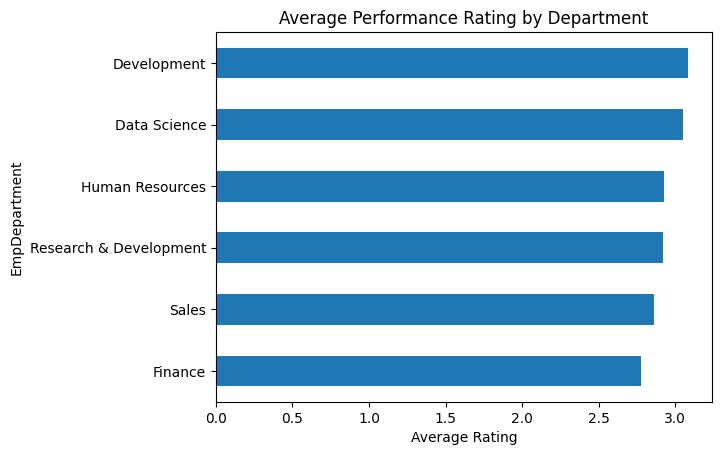

In [4]:
dept_avg = data.groupby('EmpDepartment')['PerformanceRating'].mean().sort_values()
dept_avg.plot(kind='barh')
plt.title('Average Performance Rating by Department')
plt.xlabel('Average Rating')
plt.show()

In [5]:
dept_percent = pd.crosstab(data['EmpDepartment'], data['PerformanceRating'], normalize='index') * 100
dept_percent.round(1)

PerformanceRating,2,3,4
EmpDepartment,,,
Data Science,5.0,85.0,10.0
Development,3.6,84.2,12.2
Finance,30.6,61.2,8.2
Human Resources,18.5,70.4,11.1
Research & Development,19.8,68.2,12.0
Sales,23.3,67.3,9.4


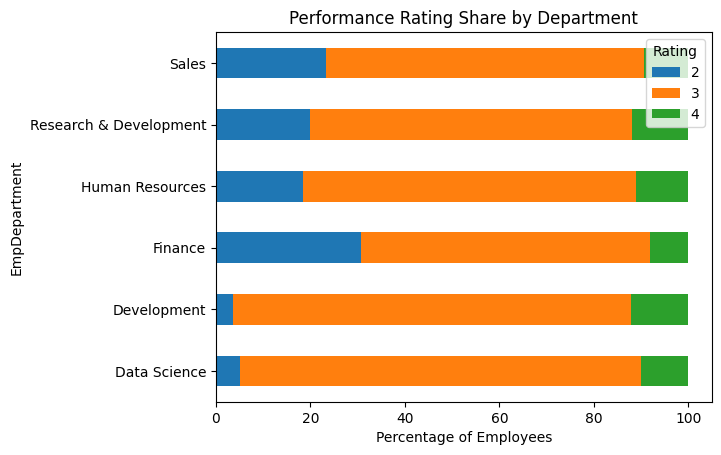

In [6]:
dept_percent.plot(kind='barh', stacked=True)
plt.title('Performance Rating Share by Department')
plt.xlabel('Percentage of Employees')
plt.legend(title='Rating')
plt.show()

### Finding: Department-wise Performance
Development has the best performance, with only about 4% of employees rated Good (2), the lowest rating in the data. Finance has the highest share rated Good (about 31%), followed by Sales (23%) and Research and Development (20%). Sales and Research and Development together hold about 80% of all employees rated Good, so improvement efforts should start there.

## Factors Affecting Performance
We load the encoded data (all numbers) and measure how strongly each column is related to the performance rating using correlation.

In [7]:
encoded_data = pd.read_csv('../../data/processed/encoded_data.csv')
encoded_data.shape

(1200, 27)

In [8]:
correlation = encoded_data.corr()['PerformanceRating'].drop('PerformanceRating')
correlation.sort_values(ascending=False)

EmpEnvironmentSatisfaction      0.395561
EmpLastSalaryHikePercent        0.333722
EmpWorkLifeBalance              0.124429
OverTime                        0.050206
MaritalStatus                   0.024172
NumCompaniesWorked              0.020980
EmpEducationLevel               0.020529
EducationBackground             0.005607
EmpJobSatisfaction              0.000606
Gender                         -0.001780
TrainingTimesLastYear          -0.005443
EmpJobInvolvement              -0.010539
EmpRelationshipSatisfaction    -0.019502
BusinessTravelFrequency        -0.031025
Attrition                      -0.039796
Age                            -0.040164
EmpHourlyRate                  -0.043116
DistanceFromHome               -0.046142
TotalWorkExperienceInYears     -0.068141
EmpJobLevel                    -0.076632
EmpJobRole                     -0.096209
ExperienceYearsAtThisCompany   -0.111645
YearsWithCurrManager           -0.122313
ExperienceYearsInCurrentRole   -0.147638
EmpDepartment   

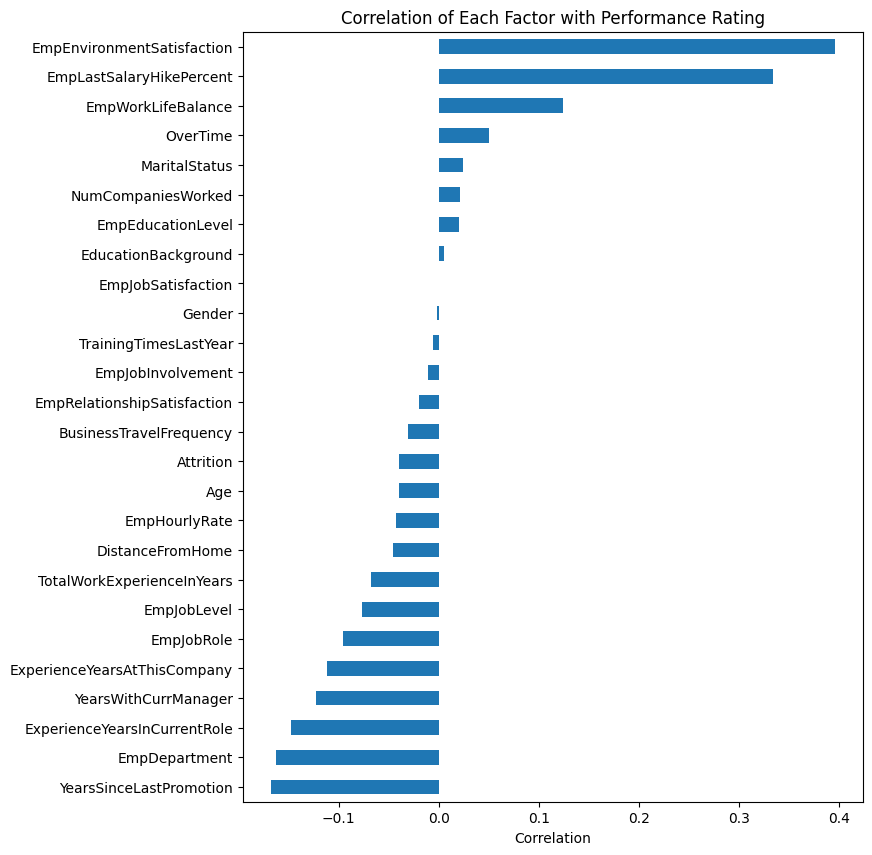

In [9]:
correlation.sort_values().plot(kind='barh', figsize=(8, 10))
plt.title('Correlation of Each Factor with Performance Rating')
plt.xlabel('Correlation')
plt.show()

### Confirming Important Factors with Random Forest
Random Forest measures how much each factor helps in predicting the rating. We compare this with the correlation results.

In [10]:
X = encoded_data.drop('PerformanceRating', axis=1)
y = encoded_data['PerformanceRating']

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

importance = pd.Series(rf.feature_importances_, index=X.columns)
importance.sort_values(ascending=False)

EmpLastSalaryHikePercent        0.214712
EmpEnvironmentSatisfaction      0.214228
YearsSinceLastPromotion         0.093374
ExperienceYearsInCurrentRole    0.040446
EmpDepartment                   0.039341
EmpJobRole                      0.039014
EmpHourlyRate                   0.034065
ExperienceYearsAtThisCompany    0.033836
Age                             0.032016
EmpWorkLifeBalance              0.029639
TotalWorkExperienceInYears      0.027385
DistanceFromHome                0.025172
YearsWithCurrManager            0.024433
TrainingTimesLastYear           0.017898
NumCompaniesWorked              0.017885
EmpEducationLevel               0.015525
EmpRelationshipSatisfaction     0.014774
EducationBackground             0.013597
EmpJobSatisfaction              0.013540
EmpJobInvolvement               0.012243
EmpJobLevel                     0.011118
MaritalStatus                   0.009972
BusinessTravelFrequency         0.009467
OverTime                        0.006198
Gender          

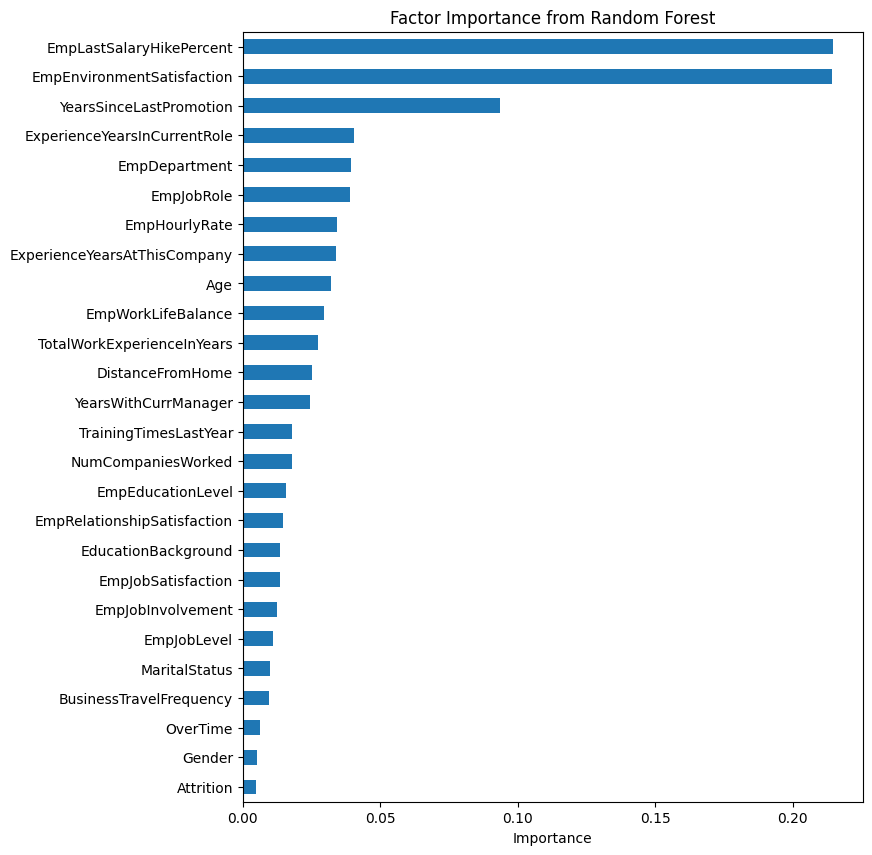

In [12]:
importance.sort_values().plot(kind='barh', figsize=(8, 10))
plt.title('Factor Importance from Random Forest')
plt.xlabel('Importance')
plt.show()

### Note on Cause and Effect
The analysis shows that last salary hike percentage, environment satisfaction and years since last promotion are strongly linked to performance rating. However, a link does not prove cause and effect. For example, employees with higher ratings may receive bigger salary hikes, so the hike may be partly a result of good performance and not only a reason for it. In the same way, employees who perform well may be promoted sooner. These findings therefore show which factors to focus on, but the company should confirm the direction of the effect (for example, by trying changes with a small group first) before making large decisions.

### Relationship of the Top 3 Factors with Performance

In [13]:
data.groupby('EmpEnvironmentSatisfaction')['PerformanceRating'].mean()

EmpEnvironmentSatisfaction
1    2.665217
2    2.652893
3    3.138965
4    3.132964
Name: PerformanceRating, dtype: float64

In [14]:
data.groupby('YearsSinceLastPromotion')['PerformanceRating'].mean()

YearsSinceLastPromotion
0     3.123667
1     2.898990
2     2.763780
3     2.777778
4     2.773585
5     2.828571
6     2.833333
7     2.854839
8     2.545455
9     2.687500
10    2.600000
11    2.826087
12    2.666667
13    3.125000
14    3.000000
15    2.909091
Name: PerformanceRating, dtype: float64

In [15]:
data.groupby('PerformanceRating')['EmpLastSalaryHikePercent'].mean()

PerformanceRating
2    15.072165
3    14.427918
4    20.704545
Name: EmpLastSalaryHikePercent, dtype: float64

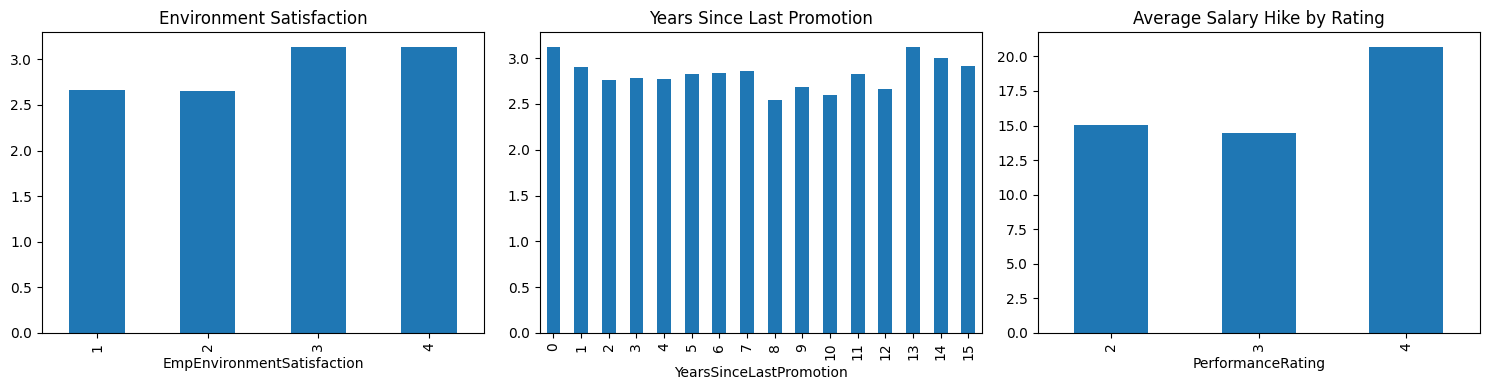

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

data.groupby('EmpEnvironmentSatisfaction')['PerformanceRating'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_title('Environment Satisfaction')

data.groupby('YearsSinceLastPromotion')['PerformanceRating'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title('Years Since Last Promotion')

data.groupby('PerformanceRating')['EmpLastSalaryHikePercent'].mean().plot(kind='bar', ax=axes[2])
axes[2].set_title('Average Salary Hike by Rating')

plt.tight_layout()
plt.show()

### Finding: Top 3 Factors Affecting Performance
1. Last salary hike percentage: Employees rated Outstanding (4) received an average hike of about 20.7%, compared with about 14 to 15% for employees rated Good (2) or Excellent (3).
2. Environment satisfaction: Employees with High or Very High satisfaction (3 or 4) have an average rating of about 3.13, compared with about 2.66 for Low or Medium satisfaction (1 or 2).
3. Years since last promotion: Employees promoted within the last year have an average rating of about 3.12, which falls to about 2.77 after two to four years without promotion.
Both correlation and Random Forest importance gave the same three factors.

## Correlation Between the Factors
Some factors may carry the same information (for example, age and total work experience). We check which factors are strongly related to each other.

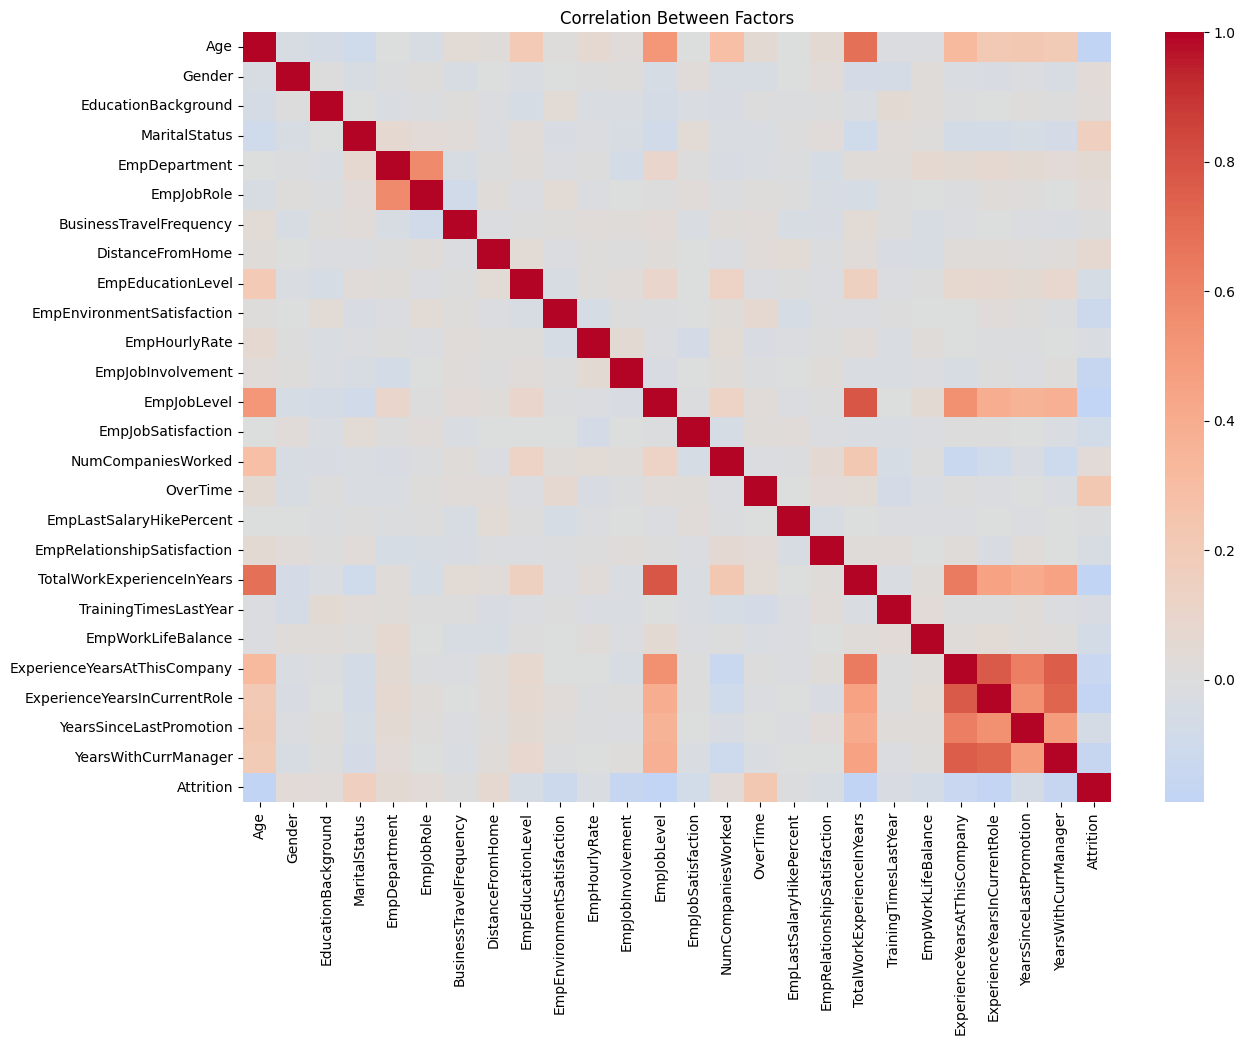

In [17]:
corr_matrix = encoded_data.drop('PerformanceRating', axis=1).corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title('Correlation Between Factors')
plt.show()

In [18]:
pairs = corr_matrix.unstack().reset_index()
pairs.columns = ['Factor 1', 'Factor 2', 'Correlation']
pairs = pairs[pairs['Factor 1'] < pairs['Factor 2']]
pairs[pairs['Correlation'].abs() > 0.5].sort_values('Correlation', ascending=False)

,Factor 1,Factor 2,Correlation
330,EmpJobLevel,TotalWorkExperienceInYears,0.784229
568,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,0.764102
570,ExperienceYearsAtThisCompany,YearsWithCurrManager,0.759258
596,ExperienceYearsInCurrentRole,YearsWithCurrManager,0.728973
18,Age,TotalWorkExperienceInYears,0.680886
564,ExperienceYearsAtThisCompany,TotalWorkExperienceInYears,0.633555
569,ExperienceYearsAtThisCompany,YearsSinceLastPromotion,0.620230
109,EmpDepartment,EmpJobRole,0.568973
595,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,0.540600
333,EmpJobLevel,ExperienceYearsAtThisCompany,0.540377
